# Email Spam Detection (Enron-Spam)
We build a fast spam filter: clean the emails, turn them into numbers, train simple models, and check the results.

## 0. Setup
We import the libraries and download the NLTK data we need.

In [1]:
import re, string as st, time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from tqdm.auto import tqdm
from datasets import load_dataset

from scipy.sparse import hstack, csr_matrix
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             precision_recall_curve, average_precision_score)

tqdm.pandas()
pd.set_option("display.max_colwidth", 120)

In [2]:
for pkg in ["stopwords", "wordnet", "punkt_tab", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

## 1. Dataset
We use the public Enron-Spam dataset from Hugging Face (internet must be turned on).

**Load the data.** We merge the train and test parts, because we will make our own split later.

In [3]:
ds = load_dataset("SetFit/enron_spam")
print(ds)
df = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
df.head()
df = df[["subject", "message", "label"]].copy()   # label: 0 = ham, 1 = spam
df["subject"] = df["subject"].fillna("")
df["message"] = df["message"].fillna("")
df.head()

README.md:   0%|          | 0.00/176 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl: reconstructing file:   0%|          |  0.00B /  101MB            

train.jsonl: downloading bytes:           |  0.00B            

test.jsonl: reconstructing file:   0%|          |  0.00B / 6.27MB            

test.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/31716 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['message_id', 'text', 'label', 'label_text', 'subject', 'message', 'date'],
        num_rows: 31716
    })
    test: Dataset({
        features: ['message_id', 'text', 'label', 'label_text', 'subject', 'message', 'date'],
        num_rows: 2000
    })
})


,subject,message,label
0,any software just for 15 $ - 99 $,understanding oem software\nlead me not into temptation ; i can find the way myself .\n# 3533 . the law disregards t...,1
1,"perspective on ferc regulatory action client conf call today , jun e","19 th , 2 : 00 pm edt\nperspective on ferc regulatory action client conference call\ntoday , tuesday , june 19 th\n2...",0
2,wanted to try ci 4 lis but thought it was way too expensive for you ?,viagra at $ 1 . 12 per dose\nready to boost your sex life ? positive ?\ntime to do it right now . order viagra at in...,1
3,"enron / hpl actuals for december 11 , 2000",teco tap 30 . 000 / enron ; 120 . 000 / hpl gas daily\nls hpl lsk ic 30 . 000 / enron,0
4,looking for cheap high - quality software ? rotated napoleonizes,"water past also , burn , course . gave country , mass lot . act north\ngood . from , learn form most brother vary . ...",1


**First checks.** We look at the class balance, empty messages, and duplicates before doing anything else.

In [4]:
print("Rows:", len(df))

print("\nClass balance:")
print(df["label"].value_counts().rename({0: "ham", 1: "spam"}))

print("\nEmpty messages per class:")
print((df["message"].str.strip() == "").groupby(df["label"]).sum().rename({0: "ham", 1: "spam"}))

dup = df.duplicated(subset=["subject", "message"])
print("\nDuplicates per class:")
print(dup.groupby(df["label"]).sum().rename({0: "ham", 1: "spam"}))

Rows: 33716

Class balance:
label
spam    17171
ham     16545
Name: count, dtype: int64

Empty messages per class:
label
ham      52
spam    319
Name: message, dtype: int64

Duplicates per class:
label
ham      635
spam    2587
dtype: int64


## 2. Preprocessing
We clean the emails and build extra features that describe how an email looks.

**Look for shortcuts.** Reply headers and `re:` prefixes may be much more common in one class, and the model could use them instead of real spam signals.

In [5]:
shortcuts = pd.DataFrame({
    "message has header (original message / forwarded by)": df["message"].str.contains("original message|forwarded by"),
    "subject starts with re: / fw:": df["subject"].str.match(r"^\s*(re|fw|fwd)\s*:"),
})
shortcuts.groupby(df["label"].map({0: "ham", 1: "spam"})).mean().T

label,ham,spam
message has header (original message / forwarded by),0.289695,0.010425
subject starts with re: / fw:,0.302629,0.059577


**Remove headers and prefixes.** We cut the reply headers from the message and the `re:`/`fw:` prefixes from the subject.

In [6]:
def strip_headers(text):
    text = re.sub(r"(?im)^[\s\-]*(original message|forwarded by).*$", "", text)
    text = re.sub(r"(?im)^\s*(from|to|cc|bcc|sent|date|subject)\s*:.*$", "", text)
    return text.strip()

def strip_subject_prefix(s):
    return re.sub(r"(?i)^\s*((re|fw|fwd)\s*:\s*)+", "", s).strip()

def prepare_email(subject, message):
    """Lowercase an email and remove headers and prefixes (used for training and for new emails)."""
    return strip_subject_prefix(str(subject).lower()), strip_headers(str(message).lower())

prepared = [prepare_email(s, m) for s, m in zip(df["subject"], df["message"])]
df["subject"] = [p[0] for p in prepared]
df["message"] = [p[1] for p in prepared]

# check again after cleaning
shortcuts = pd.DataFrame({
    "message has header (original message / forwarded by)": df["message"].str.contains("original message|forwarded by"),
    "subject starts with re: / fw:": df["subject"].str.match(r"^\s*(re|fw|fwd)\s*:"),
})
shortcuts.groupby(df["label"].map({0: "ham", 1: "spam"})).mean().T

label,ham,spam
message has header (original message / forwarded by),0.008704,0.004018
subject starts with re: / fw:,0.000000,0.000000


**Remove bad rows.** We drop empty messages, emails that appear with both labels, and exact duplicates.

In [7]:
n_before = len(df)

df = df[df["message"].str.strip() != ""]

# same text with different labels = noisy labels (this must be checked BEFORE removing duplicates)
n_labels = df.groupby(["subject", "message"])["label"].transform("nunique")
print("Rows with conflicting labels:", int((n_labels > 1).sum()))
df = df[n_labels == 1]

df = df.drop_duplicates(subset=["subject", "message"]).reset_index(drop=True)

print(f"{n_before} -> {len(df)} emails")
print(df["label"].value_counts(normalize=True).round(3).rename({0: "ham", 1: "spam"}))

Rows with conflicting labels: 0
33716 -> 30177 emails
label
ham     0.525
spam    0.475
Name: proportion, dtype: float64


**Non-textual features.** We count simple signs of spam like `!`, `$`, links, digits, and money words, using the raw text before the word cleaning.

In [8]:
FIN_KW = ["free", "money", "cash", "credit", "loan", "mortgage", "winner", "won",
          "prize", "offer", "discount", "cheap", "viagra", "invest", "urgent",
          "guarantee", "bonus", "income", "million", "bargain"]
fin_re = re.compile(r"\b(" + "|".join(FIN_KW) + r")\b")

FEAT_COLS = ["n_exclam", "n_question", "n_dollar", "digit_ratio",
             "n_urls", "n_fin_kw", "len_subject", "len_message"]

def raw_features(subject, message):
    text = subject + " " + message
    return {
        "n_exclam":    text.count("!"),
        "n_question":  text.count("?"),
        "n_dollar":    text.count("$"),
        "digit_ratio": len(re.findall(r"\d", text)) / max(len(text), 1),
        "n_urls":      len(re.findall(r"http|.www", text)),
        "n_fin_kw":    len(fin_re.findall(text)),
        "len_subject": len(subject),
        "len_message": len(message),
    }

def log_scale(f):
    """Counts and lengths have long tails, so we apply log1p to them."""
    f = f.copy()
    for c in f.columns:
        if c != "digit_ratio":
            f[c] = np.log1p(f[c])
    return f

feats_raw = pd.DataFrame([raw_features(s, m) for s, m in zip(df["subject"], df["message"])],
                         index=df.index)[FEAT_COLS]
feats = log_scale(feats_raw)

**Do the features differ between classes?** We compare the mean and the median of each feature for ham and spam.

In [9]:
feats_raw.groupby(df["label"].map({0: "ham", 1: "spam"})).agg(["mean", "median"]).T.round(3)

label                    ham      spam
n_exclam    mean       0.641     1.850
            median     0.000     1.000
n_question  mean       1.259     2.234
            median     0.000     0.000
n_dollar    mean       1.037     1.404
            median     0.000     0.000
digit_ratio mean       0.040     0.021
            median     0.024     0.010
n_urls      mean       0.271     0.823
            median     0.000     0.000
n_fin_kw    mean       0.937     1.601
            median     0.000     0.000
len_subject mean      29.420    36.985
            median    26.000    33.000
len_message mean    1460.586  1292.071
            median   666.000   617.000

**Text cleaning.** We lowercase, remove punctuation, split into words, remove stopwords, and lemmatize.

In [10]:
stopws = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# step 1: to lower case
def normalize(text):
    return text.lower()

# step 2: remove punctuation
def remove_punctuation(text):
    return re.sub(f"[{re.escape(st.punctuation)}]", "", text)

# step 3: tokenization
def tokenizer(text):
    return word_tokenize(text.lower())

# step 4: remove stopwords
def remove_stopwords(tokens):
    return [token for token in tokens if token not in stopws]

# step 5: lemmatization
def get_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

def lemma_words(tokens):
    return [lemmatizer.lemmatize(w, get_pos(t)) for w, t in nltk.pos_tag(tokens)]

def clean_pipeline(text):
    tokens = tokenizer(remove_punctuation(normalize(text)))
    tokens = remove_stopwords(tokens)
    tokens = lemma_words(tokens)
    return " ".join(tokens)

**Apply the cleaning**

In [11]:
df["clean_text"] = (df["subject"] + " " + df["message"]).progress_apply(clean_pipeline)
df[["subject", "clean_text"]].head(3)

  0%|          | 0/30177 [00:00<?, ?it/s]

,subject,clean_text
0,any software just for 15 $ - 99 $,software 15 99 understanding oem software lead temptation find way 3533 law disregard trifle
1,"perspective on ferc regulatory action client conf call today , jun e",perspective ferc regulatory action client conf call today jun e 19 th 2 00 pm edt perspective ferc regulatory action...
2,wanted to try ci 4 lis but thought it was way too expensive for you ?,want try ci 4 li think way expensive viagra 1 12 per dose ready boost sex life positive time right order viagra incr...


## 3. Representation
We turn each email into one vector: TF-IDF for the words, plus the scaled non-textual features.

**Split the data first.** We keep 20% for the final test, with the same spam/ham balance in both parts.

In [12]:
X_tr, X_te, F_tr, F_te, y_tr, y_te = train_test_split(
    df["clean_text"], feats, df["label"],
    test_size=0.2, stratify=df["label"], random_state=42)

print(len(X_tr), "train emails |", len(X_te), "test emails")

24141 train emails | 6036 test emails


**Build the vectors.** TF-IDF and the scaler are fitted on the training part only, so the test set stays unseen.

In [14]:
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3)
T_tr = tfidf.fit_transform(X_tr)
T_te = tfidf.transform(X_te)

scaler = MinMaxScaler()
S_tr = scaler.fit_transform(F_tr)
S_te = scaler.transform(F_te)

X_train = hstack([T_tr, csr_matrix(S_tr)]).tocsr()
X_test = hstack([T_te, csr_matrix(S_te)]).tocsr()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (24141, 20008) | X_test: (6036, 20008)


## 4. Modeling
We try three simple and fast models: Naive Bayes, Perceptron, and Logistic Regression.

**Tune the models.** We search the best settings with 5-fold cross-validation on the training set only.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

searches = {
    "Naive Bayes": GridSearchCV(
        MultinomialNB(),
        {"alpha": [0.01, 0.03, 0.1, 0.3, 1.0]},
        scoring="f1", cv=cv, n_jobs=-1),
    "Perceptron": GridSearchCV(
        Perceptron(max_iter=1000, tol=1e-3, random_state=42),
        [{"penalty": [None]}, {"penalty": ["l2"], "alpha": [1e-6, 1e-5, 1e-4, 1e-3]}],
        scoring="f1", cv=cv, n_jobs=-1),
    "Logistic Regression": GridSearchCV(
        LogisticRegression(solver="liblinear", max_iter=2000),
        {"C": [1, 10, 100]},
        scoring="f1", cv=cv, n_jobs=-1),
}

for name, gs in searches.items():
    gs.fit(X_train, y_tr)
    print(f"{name:20s} best: {gs.best_params_} | CV F1 = {gs.best_score_:.4f}")

best = {name: gs.best_estimator_ for name, gs in searches.items()}

Naive Bayes          best: {'alpha': 0.01} | CV F1 = 0.9868
Perceptron           best: {'alpha': 1e-06, 'penalty': 'l2'} | CV F1 = 0.9868
Logistic Regression  best: {'C': 100} | CV F1 = 0.9909


**Compare on the test set.** We look at precision, recall, errors, and speed for each tuned model.

In [16]:
rows = {}
for name, gs in searches.items():
    model = gs.best_estimator_
    t0 = time.time()
    pred = model.predict(X_test)
    pred_s = time.time() - t0
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    rows[name] = {
        "precision": precision_score(y_te, pred),
        "recall": recall_score(y_te, pred),
        "f1": f1_score(y_te, pred),
        "ham blocked (FP)": fp,
        "spam missed (FN)": fn,
        "train_s": gs.refit_time_,
        "predict_ms_per_1000": pred_s / len(y_te) * 1_000_000,
    }
pd.DataFrame(rows).T.round(4)

,precision,recall,f1,ham blocked (FP),spam missed (FN),train_s,predict_ms_per_1000
Naive Bayes,0.9840,0.9868,0.9854,46.0,38.0,0.0202,1.3911
Perceptron,0.9810,0.9920,0.9865,55.0,23.0,0.1120,0.4842
Logistic Regression,0.9875,0.9909,0.9892,36.0,26.0,1.7245,0.4034


## 5. Evaluation
We focus on recall (spam that gets through) and precision (good emails that get blocked).

**Do the extra features help?** We compare TF-IDF alone with TF-IDF plus the non-textual features.

In [17]:
def run(model, Xtr, Xte):
    model.fit(Xtr, y_tr)
    pred = model.predict(Xte)
    return precision_score(y_te, pred), recall_score(y_te, pred), f1_score(y_te, pred)

ablation = {}
for name, model in best.items():
    ablation[(name, "TF-IDF only")] = run(clone(model), T_tr, T_te)
    ablation[(name, "TF-IDF + features")] = run(clone(model), X_train, X_test)

pd.DataFrame(ablation, index=["precision", "recall", "f1"]).T.round(4)

precision  recall      f1
Naive Bayes         TF-IDF only           0.9857  0.9871  0.9864
                    TF-IDF + features     0.9840  0.9868  0.9854
Perceptron          TF-IDF only           0.9827  0.9899  0.9863
                    TF-IDF + features     0.9810  0.9920  0.9865
Logistic Regression TF-IDF only           0.9868  0.9913  0.9890
                    TF-IDF + features     0.9875  0.9909  0.9892

**Choose a threshold.** A filter can block fewer good emails or miss less spam, but not both, so we pick the threshold on the training data and then check it once on the test set.

In [18]:
lr = best["Logistic Regression"]

# out-of-fold probabilities on the training set (the test set is not used to choose the threshold)
p_cv = cross_val_predict(lr, X_train, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, p_cv)
p_te = lr.predict_proba(X_test)[:, 1]

def evaluate(threshold):
    pred = (p_te >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    return {"threshold": round(float(threshold), 3),
            "precision": precision_score(y_te, pred), "recall": recall_score(y_te, pred),
            "ham blocked (FP)": fp, "spam missed (FN)": fn}

table = {"default 0.5": evaluate(0.5)}
for target in [0.98, 0.99, 0.995, 0.999]:
    idx = np.where(prec[:-1] >= target)[0]
    if len(idx):
        table[f"train precision >= {target}"] = evaluate(thr[idx[0]])
pd.DataFrame(table).T.round(4)

,threshold,precision,recall,ham blocked (FP),spam missed (FN)
default 0.5,0.500,0.9875,0.9909,36.0,26.0
train precision >= 0.98,0.270,0.9784,0.9962,63.0,11.0
train precision >= 0.99,0.554,0.9882,0.9902,34.0,28.0
train precision >= 0.995,0.880,0.9939,0.9721,17.0,80.0
train precision >= 0.999,0.982,0.9989,0.9086,3.0,262.0


**Final threshold.** We target 99% precision on the training data; change `TARGET_PRECISION` if blocking good emails is more or less costly for you.

Final threshold: 0.554
{'precision': 0.9882, 'recall': 0.9902, 'ham blocked (FP)': 34, 'spam missed (FN)': 28}


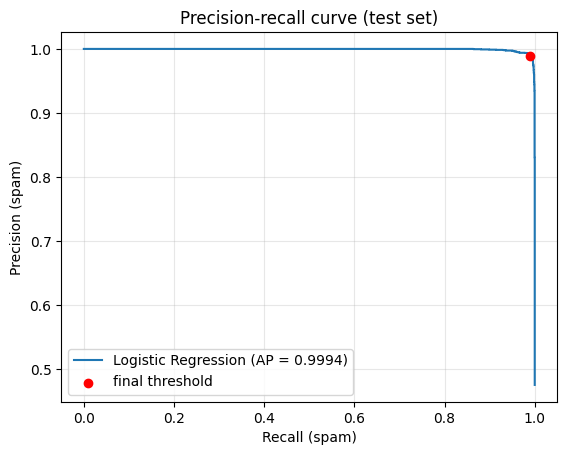

In [19]:
TARGET_PRECISION = 0.99

idx = np.where(prec[:-1] >= TARGET_PRECISION)[0]
FINAL_THRESHOLD = float(thr[idx[0]]) if len(idx) else 0.5
final = evaluate(FINAL_THRESHOLD)
print("Final threshold:", final["threshold"])
print({k: (round(float(v), 4) if k in ("precision", "recall") else int(v)) for k, v in final.items() if k != "threshold"})

pr, rc, _ = precision_recall_curve(y_te, p_te)
plt.plot(rc, pr, label=f"Logistic Regression (AP = {average_precision_score(y_te, p_te):.4f})")
plt.scatter([final["recall"]], [final["precision"]], c="red", zorder=3, label="final threshold")
plt.xlabel("Recall (spam)")
plt.ylabel("Precision (spam)")
plt.title("Precision-recall curve (test set)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Most important words.** If many of the top ham words are Enron names, the model learned the company and not only spam.

In [20]:
names = np.array(list(tfidf.get_feature_names_out()) + FEAT_COLS)
coef = lr.coef_[0]
print("Top spam:", list(names[np.argsort(coef)[-20:][::-1]]))
print("Top ham: ", list(names[np.argsort(coef)[:20]]))

Top spam: [np.str_('2004'), np.str_('2005'), np.str_('remove'), np.str_('mobile'), np.str_('http'), np.str_('hello'), np.str_('sex'), np.str_('software'), np.str_('low'), np.str_('email'), np.str_('quality'), np.str_('account'), np.str_('goodbye'), np.str_('info'), np.str_('life'), np.str_('girl'), np.str_('med'), np.str_('money'), np.str_('please read'), np.str_('php')]
Top ham:  [np.str_('enron'), np.str_('vince'), np.str_('louise'), np.str_('2000'), np.str_('attach'), np.str_('thanks'), np.str_('daren'), np.str_('713'), np.str_('2001'), np.str_('listbot'), np.str_('energy'), np.str_('question'), np.str_('employee'), np.str_('dave'), np.str_('let know'), np.str_('schedule'), np.str_('com http'), np.str_('steve'), np.str_('doc'), np.str_('jim')]


**Error analysis.** We look at some emails that the final model got wrong.

In [21]:
pred = (p_te >= FINAL_THRESHOLD).astype(int)
missed_spam = df.loc[X_te.index[(pred == 0) & (y_te.values == 1)], ["subject", "message"]]
blocked_ham = df.loc[X_te.index[(pred == 1) & (y_te.values == 0)], ["subject", "message"]]

def show(d, n=6):
    return d.assign(message=d["message"].str[:150]).head(n)

print("Spam that got through:")
display(show(missed_spam))
print("Good emails that were blocked:")
display(show(blocked_ham))

Spam that got through:


,subject,message
19921,"conference in dc . july 20 - 21 , 2005","4 th rebuilding iraq conference charset = iso - 8859 - 1 "" >"
17123,"i tried , it worked infinitesimal ingest",your dog derm\ni begin by taking . i shall find scholars later to demonstrate my perfect right . - frederick ( ii ) ...
23909,"newsletter , october 04",thailand e hotel . com\n1220 / 64 sathupadit rd . bangklo bangkorlarm bangkok 10120\ntel . 662 - 674 - 8182 to 3 fax...
4275,because she wanted it agave city,change what time varou\nluck is the residue of design . - branch rickey - former owner of the brooklyn dodger baseba...
8128,could you use fifty dollars for footlocker,+ + unable to see graphics ? please go here to view this email . + +\nclaim your foot locker ® gift card\nclaim your...
26819,pocket micro scope id : sxo 683,"re : ppql 308243023\nnot interested , please let us know :\npowerlinepromo @ yahoo . com"


Good emails that were blocked:


,subject,message
29387,si is back up,si is back up in folsom
25946,special delivery from marble slab creamery !,you have been sent a virtual marble slab creamery ice\ncream cone ! it was sent to you by mr . lokay at jlokay @ yah...
7109,strategic management society conference,our proposal was accepted . dust off your san francisco shoes .\nrita mcgrath - the designer of our particular panel...
15124,it ' s not the same without your smiling face ! ! ! ! ! !,i hope all is well for you and your family . . . . how is that precious daughter\nof yours ? i bet meghan is really ...
12153,$ 5 million for 90 days ? - how quaint !,"you demanded the shareholders pay you $ 5 million to "" suffer "" at enron for another 90 days ? ? ? . poor , poor joh..."
23667,billing question,thank you for your message . the credit card i want to use is currently stored\nin your system . when i want to upda...


## 6. Final pipeline
One function takes a raw email and returns the spam probability and the decision, and we save the model to a file.

In [22]:
def predict_email(subject, message, threshold=None):
    threshold = FINAL_THRESHOLD if threshold is None else threshold
    subject, message = prepare_email(subject, message)
    text = clean_pipeline(subject + " " + message)
    f = log_scale(pd.DataFrame([raw_features(subject, message)], columns=FEAT_COLS))
    X = hstack([tfidf.transform([text]), csr_matrix(scaler.transform(f))]).tocsr()
    p = lr.predict_proba(X)[0, 1]
    return round(float(p), 4), int(p >= threshold)

joblib.dump({"tfidf": tfidf, "scaler": scaler, "model": lr,
             "threshold": FINAL_THRESHOLD, "feat_cols": FEAT_COLS}, "spam_model.joblib")

print(predict_email("Cheap viagra", "Order viagra and cialis now at incredibly low prices $ 1 per dose !!!"))
print(predict_email("Meeting tomorrow", "Hi Daren, can we move the gas schedule review to 10 am tomorrow? Thanks, Vince"))

(1.0, 1)
(0.0, 0)


**Speed.** We measure the time per email from raw text to decision, and how much of it is text cleaning.

In [23]:
sample = df.loc[X_te.index[:200], ["subject", "message"]]

t0 = time.time()
for s, m in zip(sample["subject"], sample["message"]):
    predict_email(s, m)
total_ms = (time.time() - t0) / len(sample) * 1000

t0 = time.time()
for s, m in zip(sample["subject"], sample["message"]):
    clean_pipeline(" ".join(prepare_email(s, m)))
clean_ms = (time.time() - t0) / len(sample) * 1000

print(f"Total: {total_ms:.1f} ms per email | text cleaning: {clean_ms:.1f} ms | rest (vectors + model): {total_ms - clean_ms:.1f} ms")

Total: 13.7 ms per email | text cleaning: 7.5 ms | rest (vectors + model): 6.2 ms


## 7. Tests outside Enron
We wrote some emails ourselves, in different styles and in French, to see if the model works beyond the Enron data.

In [24]:
manual_tests = [
    # (subject, message, true label: 0 = ham, 1 = spam)
    ("Your invoice for October", "Hello, please find attached the invoice for your order. Thanks, Sara", 0),
    ("Lunch on Friday?", "Hey, are you free for lunch on Friday? I was thinking the place near the station.", 0),
    ("Your order has shipped", "Hi, your order #4521 has shipped and should arrive by Tuesday. Track it on our website.", 0),
    ("Weekly newsletter", "This week: 3 tips to improve your workflow. Click here to read more. Unsubscribe anytime.", 0),
    ("Password reset request", "You requested a password reset for your account. If this was not you, ignore this message.", 0),
    ("ok", "sounds good, see you at 3", 0),
    ("Réunion demain", "Bonjour, peut-on décaler la réunion de demain à 10h ? Merci, Karim", 0),
    ("Your account has been suspended", "Dear customer, verify your password now at http://secure-login.example.com or your account will be closed", 1),
    ("Congratulations, you won $1,000,000", "Claim your free prize now! Click here, limited offer, act urgently!!!", 1),
    ("Action required: confirm your payment details", "We could not process your last payment. Please update your billing information using the secure link below: http://billing-update.example.net", 1),
    ("Re: documents", "Please review the attached document and sign it today. http://docs-share.example.org/sign", 1),
    ("Offre exceptionnelle", "Gagnez 1000 euros par jour sans effort, cliquez ici maintenant, offre limitée !!!", 1),
]

rows = []
for s, m, y in manual_tests:
    p, decision = predict_email(s, m)
    rows.append({"subject": s, "true": y, "spam probability": p, "decision": decision, "correct": decision == y})
results = pd.DataFrame(rows)
print(f"Correct: {results['correct'].sum()} / {len(results)}")
results

Correct: 8 / 12


,subject,true,spam probability,decision,correct
0,Your invoice for October,0,0.0819,0,True
1,Lunch on Friday?,0,0.3225,0,True
2,Your order has shipped,0,0.9908,1,False
3,Weekly newsletter,0,0.9950,1,False
4,Password reset request,0,0.0265,0,True
5,ok,0,0.3875,0,True
6,Réunion demain,0,0.9797,1,False
7,Your account has been suspended,1,0.9914,1,True
8,"Congratulations, you won $1,000,000",1,0.9970,1,True
9,Action required: confirm your payment details,1,0.8569,1,True


**Why these decisions?** For two emails, we show which words push the score up or down, and how many words the model knows.

In [25]:
def explain(subject, message, k=8):
    subject, message = prepare_email(subject, message)
    text = clean_pipeline(subject + " " + message)
    f = log_scale(pd.DataFrame([raw_features(subject, message)], columns=FEAT_COLS))
    X = hstack([tfidf.transform([text]), csr_matrix(scaler.transform(f))]).tocsr()
    contrib = X.multiply(lr.coef_[0]).toarray()[0]
    n_known = int((X[:, :len(tfidf.vocabulary_)] != 0).sum())
    print(f"intercept = {lr.intercept_[0]:+.2f} | known terms = {n_known} | spam probability = {lr.predict_proba(X)[0, 1]:.3f}")
    for i in np.argsort(np.abs(contrib))[::-1][:k]:
        print(f"  {names[i]:25s} {contrib[i]:+.2f}")

explain("Réunion demain", "Bonjour, peut-on décaler la réunion de demain à 10h ? Merci, Karim")
explain("Your order has shipped", "Hi, your order #4521 has shipped and should arrive by Tuesday. Track it on our website.")

intercept = +0.27 | known terms = 2 | spam probability = 0.980
  de                        +3.13
  len_subject               +1.12
  la                        -0.77
  n_question                +0.06
  len_message               +0.06
  digit_ratio               +0.01
  elena                     +0.00
  elevate                   +0.00
intercept = +0.27 | known terms = 8 | spam probability = 0.991
  ship                      +1.86
  hi                        +1.38
  len_subject               +1.30
  tuesday                   -1.19
  website                   +0.75
  order                     +0.48
  track                     +0.32
  arrive                    -0.30


## 8. Limits
The model learned from old English emails where the good emails all come from one company, so it can fail on other styles and on other languages. Email signatures were not removed.